# Etapa 1 - Entendimento, EDA e Baseline

Este notebook cobre a exploracao dos dados do Telco Customer Churn, a definicao das metricas e o treino do modelo baseline com Regressao Logistica. O codigo reutilizavel fica em `src/churn`, e aqui ficam apenas a experimentacao e as conclusoes.

In [1]:
import sys
sys.path.append("../src")

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, f1_score, precision_score, recall_score)

from churn.config import (SEED, CV_FOLDS, FIGURES_DIR, RESULTS_DIR, NUMERIC_FEATURES,
                          CATEGORICAL_FEATURES, TARGET)
from churn.data import load_raw_data, clean_data, make_train_test
from churn.preprocessing import build_preprocessor

warnings.filterwarnings("ignore")
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Volume e qualidade dos dados

In [2]:
raw = load_raw_data()
print("Formato bruto:", raw.shape)
raw.head()

Formato bruto: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.dtypes.to_frame("tipo").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
tipo,str,str,int64,str,str,int64,str,str,str,str,...,str,str,str,str,str,str,str,float64,str,str


In [4]:
# TotalCharges chega como texto. Verificamos quais linhas nao viram numero.
bad = raw[pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()]
print("Linhas com TotalCharges invalido:", len(bad))
bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Linhas com TotalCharges invalido: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Os 11 registros com `TotalCharges` em branco tem `tenure` igual a 0, ou seja, sao clientes que acabaram de entrar e ainda nao foram cobrados. Nenhum deles cancelou. Mantemos as linhas e deixamos o valor ausente para ser imputado dentro do pipeline, o que evita vazamento de informacao entre treino e teste.

In [5]:
df = clean_data(raw)
print("Duplicados:", df.duplicated().sum())
print("Valores ausentes por coluna (apenas colunas com ausentes):")
print(df.isna().sum()[df.isna().sum() > 0])
print("IDs unicos no bruto:", raw["customerID"].nunique(), "de", len(raw))

Duplicados: 22
Valores ausentes por coluna (apenas colunas com ausentes):
TotalCharges    11
dtype: int64
IDs unicos no bruto: 7043 de 7043


## 2. Distribuicao do alvo

            clientes  percentual
Churn                           
Permaneceu      5174        73.5
Cancelou        1869        26.5


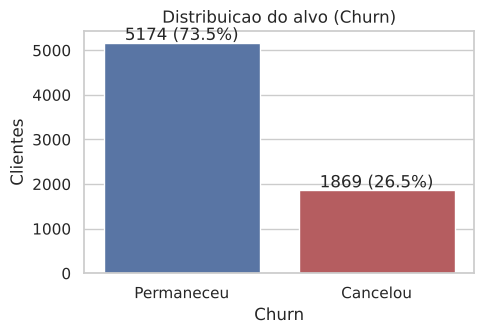

In [6]:
counts = df[TARGET].value_counts().rename({0: "Permaneceu", 1: "Cancelou"})
pct = (counts / len(df) * 100).round(1)
print(pd.DataFrame({"clientes": counts, "percentual": pct}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_title("Distribuicao do alvo (Churn)")
ax.set_ylabel("Clientes")
for i, v in enumerate(counts.values):
    ax.text(i, v + 60, f"{v} ({pct.values[i]}%)", ha="center")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_distribuicao_alvo.png", dpi=150)
plt.show()

Cerca de 26,5% dos clientes cancelaram. O problema e desbalanceado, entao a acuracia sozinha engana (um modelo que sempre prevê "permaneceu" acertaria cerca de 73%). Por isso a metrica principal sera o ROC-AUC, apoiada por F1, recall e precisao da classe churn.

## 3. Variaveis numericas

In [7]:
df[NUMERIC_FEATURES].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


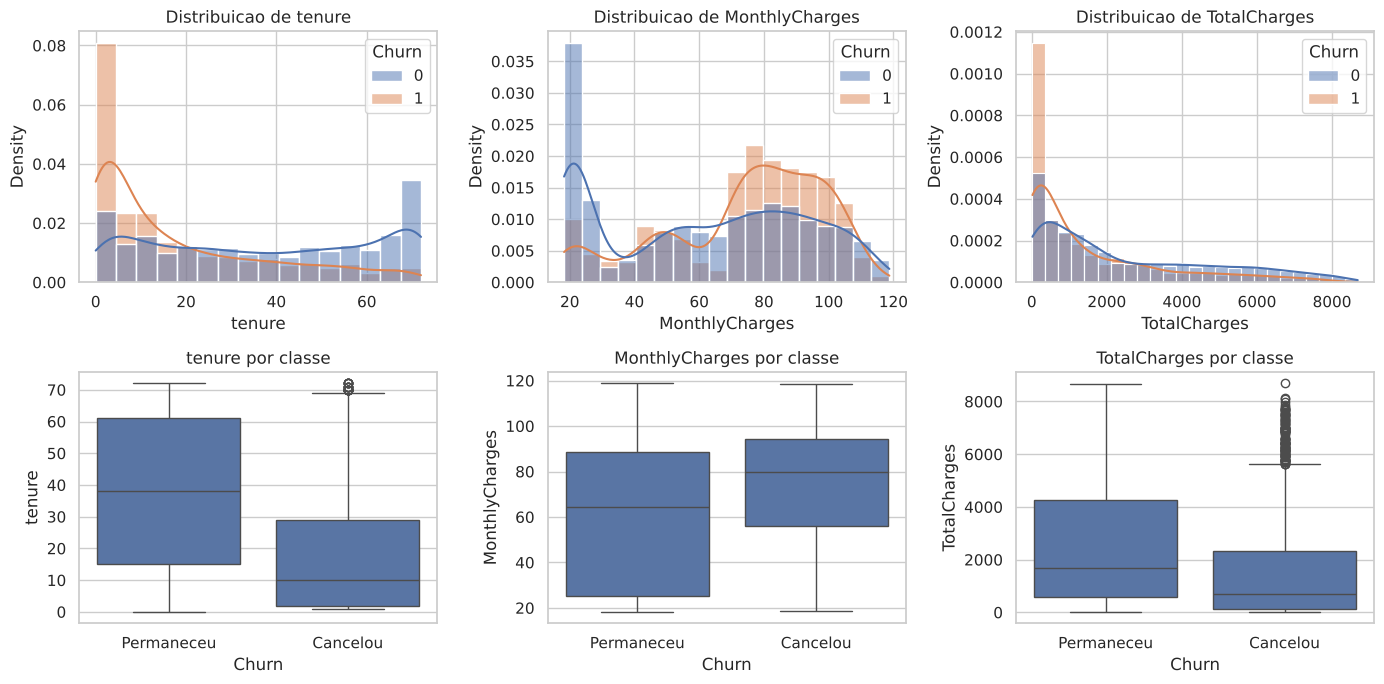

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(NUMERIC_FEATURES):
    sns.histplot(data=df, x=col, hue=TARGET, kde=True, ax=axes[0, i], stat="density", common_norm=False)
    axes[0, i].set_title(f"Distribuicao de {col}")
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[1, i])
    axes[1, i].set_xticklabels(["Permaneceu", "Cancelou"])
    axes[1, i].set_title(f"{col} por classe")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_numericas.png", dpi=150)
plt.show()

In [9]:
print(df.groupby(TARGET)[NUMERIC_FEATURES].median().round(2).rename(index={0: "Permaneceu", 1: "Cancelou"}))

            tenure  MonthlyCharges  TotalCharges
Churn                                           
Permaneceu    38.0           64.43       1683.60
Cancelou      10.0           79.65        703.55


Quem cancela tem tenure bem menor (mediana de 10 meses contra 38 de quem fica) e paga mensalidade mais alta (mediana de R$ 79,65 contra R$ 64,43). O `TotalCharges` acompanha o tenure, ja que e aproximadamente `tenure * MonthlyCharges`, o que explica a correlacao alta entre as duas colunas.

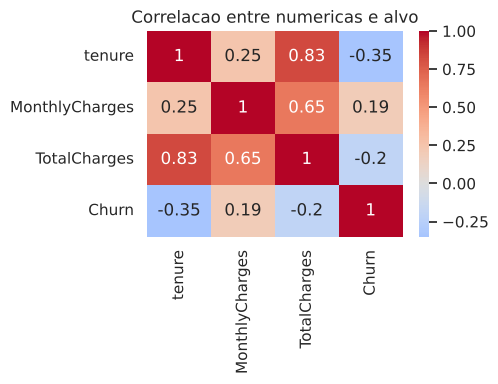

In [10]:
corr = df[NUMERIC_FEATURES + [TARGET]].corr().round(2)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlacao entre numericas e alvo")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_correlacao.png", dpi=150)
plt.show()

## 4. Variaveis categoricas e taxa de churn

In [11]:
rows = []
for col in CATEGORICAL_FEATURES:
    t = df.groupby(col)[TARGET].agg(["mean", "count"]).reset_index()
    t.columns = ["categoria", "taxa_churn", "clientes"]
    t.insert(0, "variavel", col)
    rows.append(t)
rates = pd.concat(rows)
rates["taxa_churn"] = (rates["taxa_churn"] * 100).round(1)
rates.sort_values("taxa_churn", ascending=False).head(12)

,variavel,categoria,taxa_churn,clientes
2,PaymentMethod,Electronic check,45.3,2365
0,Contract,Month-to-month,42.7,3875
1,InternetService,Fiber optic,41.9,3096
0,OnlineSecurity,No,41.8,3498
1,SeniorCitizen,1,41.7,1142
0,TechSupport,No,41.6,3473
0,OnlineBackup,No,39.9,3088
0,DeviceProtection,No,39.1,3095
0,StreamingMovies,No,33.7,2785
1,PaperlessBilling,Yes,33.6,4171


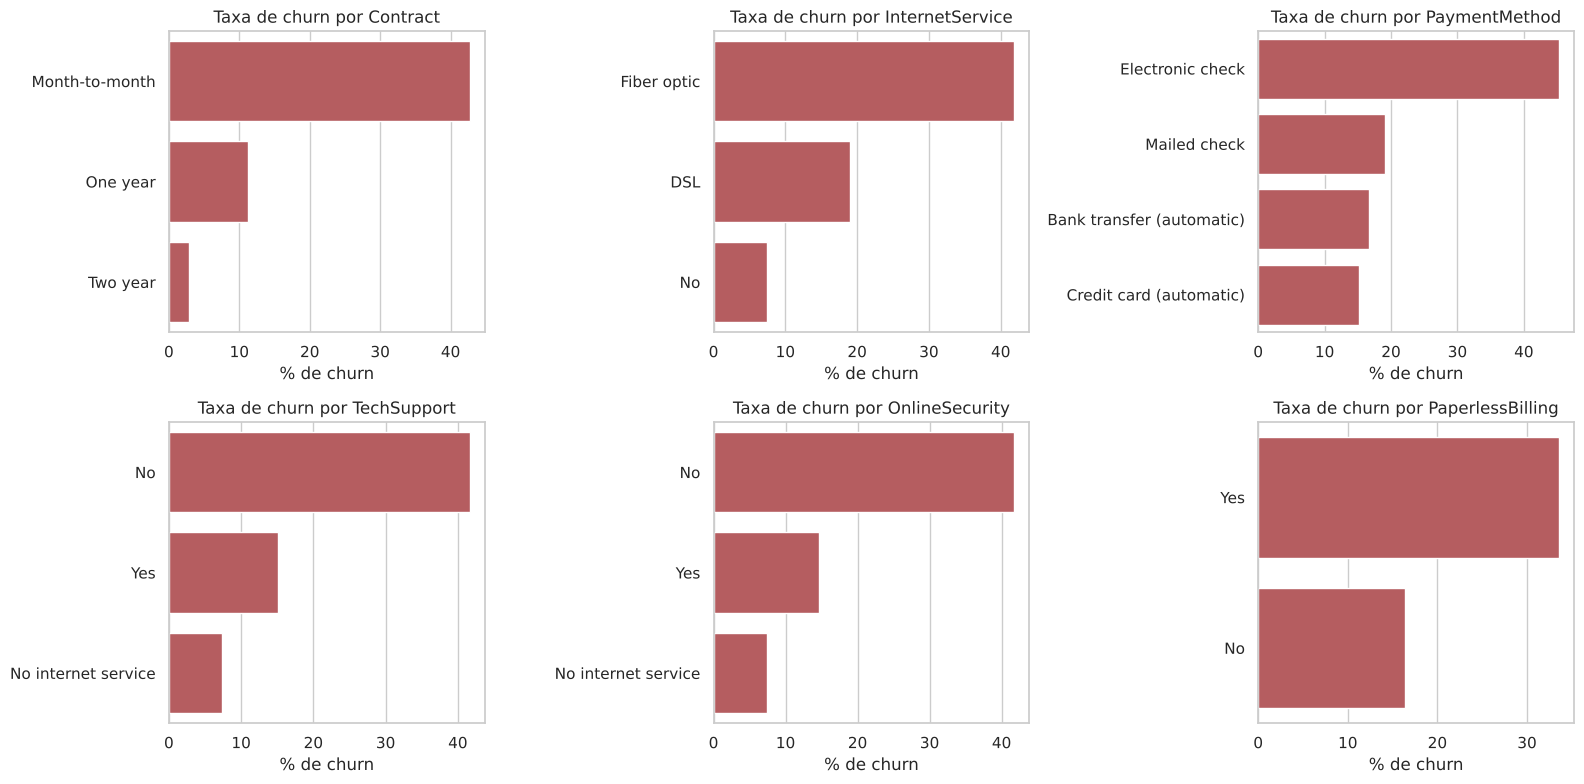

In [12]:
key_cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), key_cols):
    r = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.values, y=r.index, ax=ax, color="#C44E52")
    ax.set_title(f"Taxa de churn por {col}")
    ax.set_xlabel("% de churn")
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_churn_por_categoria.png", dpi=150)
plt.show()

Principais achados da EDA.

- Contratos mensais concentram o churn (42,7%), enquanto contratos de um ano (11,3%) e dois anos (2,8%) retem muito mais.
- Internet de fibra otica tem 41,9% de churn, contra 19,0% no DSL e 7,4% sem internet.
- Clientes sem suporte tecnico e sem seguranca online cancelam mais.
- Pagamento por cheque eletronico tem a maior taxa de cancelamento (45,3%), contra 15% a 19% nos demais meios.
- Genero (26,9% contra 26,2%) e uso de servico de telefone (24,9% contra 26,7%) quase nao diferenciam as classes.

Esses sinais orientam a expectativa de que tenure, tipo de contrato, internet e mensalidade serao as variaveis mais relevantes.

## 5. Metricas definidas

| Tipo | Metrica | Motivo |
|---|---|---|
| Tecnica principal | ROC-AUC | Mede o ranqueamento sem depender de limiar e funciona com classes desbalanceadas |
| Tecnica de apoio | F1, recall e precisao da classe churn | Mostram o equilibrio entre achar churners e nao abordar clientes a toa |
| Negocio | Valor liquido da campanha de retencao | Converte acertos e erros em reais com as premissas do ML Canvas |

O recall e importante porque perder um churner custa mais do que abordar um cliente que ficaria. A precisao controla o custo da campanha.

## 6. Baseline com Regressao Logistica

In [13]:
X_train, X_test, y_train, y_test = make_train_test(df)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Taxa de churn treino:", round(y_train.mean(), 4), "| teste:", round(y_test.mean(), 4))

Treino: (5634, 19) | Teste: (1409, 19)
Taxa de churn treino: 0.2654 | teste: 0.2654


In [14]:
baseline = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall"}
cv_res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=scoring)
cv_summary = {k.replace("test_", ""): (round(v.mean(), 4), round(v.std(), 4))
              for k, v in cv_res.items() if k.startswith("test_")}
pd.DataFrame(cv_summary, index=["media", "desvio"]).T

,media,desvio
roc_auc,0.8460,0.0124
f1,0.6286,0.0232
precision,0.5174,0.0188
recall,0.8013,0.0379


In [15]:
baseline.fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

test_metrics = {
    "roc_auc": roc_auc_score(y_test, proba),
    "f1": f1_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
}
print({k: round(v, 4) for k, v in test_metrics.items()})
print()
print(classification_report(y_test, pred, target_names=["Permaneceu", "Cancelou"]))

{'roc_auc': 0.8414, 'f1': 0.613, 'precision': 0.5034, 'recall': 0.7834}

              precision    recall  f1-score   support

  Permaneceu       0.90      0.72      0.80      1035
    Cancelou       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



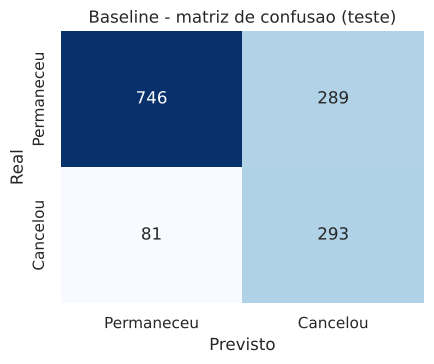

In [16]:
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Permaneceu", "Cancelou"], yticklabels=["Permaneceu", "Cancelou"])
ax.set_xlabel("Previsto"); ax.set_ylabel("Real")
ax.set_title("Baseline - matriz de confusao (teste)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_baseline_confusao.png", dpi=150)
plt.show()

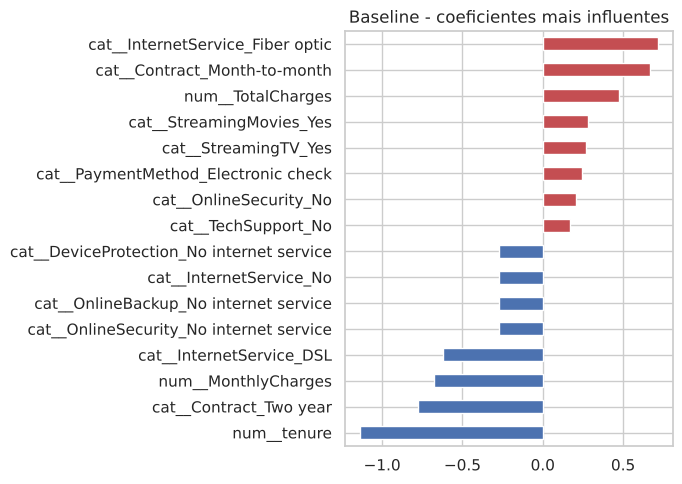

In [17]:
names = baseline.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(baseline.named_steps["clf"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])
fig, ax = plt.subplots(figsize=(7, 5))
top.plot.barh(ax=ax, color=["#4C72B0" if v < 0 else "#C44E52" for v in top.values])
ax.set_title("Baseline - coeficientes mais influentes")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_baseline_coeficientes.png", dpi=150)
plt.show()

In [18]:
out = {
    "model": "LogisticRegression (baseline)",
    "cv_5fold_train": {k: {"mean": v[0], "std": v[1]} for k, v in cv_summary.items()},
    "test": {k: round(v, 4) for k, v in test_metrics.items()},
}
with open(RESULTS_DIR / "baseline_metrics.json", "w", encoding="utf-8") as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
out

{'model': 'LogisticRegression (baseline)',
 'cv_5fold_train': {'roc_auc': {'mean': np.float64(0.846),
   'std': np.float64(0.0124)},
  'f1': {'mean': np.float64(0.6286), 'std': np.float64(0.0232)},
  'precision': {'mean': np.float64(0.5174), 'std': np.float64(0.0188)},
  'recall': {'mean': np.float64(0.8013), 'std': np.float64(0.0379)}},
 'test': {'roc_auc': 0.8414,
  'f1': 0.613,
  'precision': 0.5034,
  'recall': 0.7834}}

## 7. Conclusoes da Etapa 1

- O dataset tem 7.043 clientes, quase sem problemas de qualidade (apenas 11 `TotalCharges` ausentes, todos de clientes novos).
- O alvo e desbalanceado (cerca de 26,5% de churn), o que justifica ROC-AUC como metrica principal e `class_weight="balanced"` no baseline.
- A Regressao Logistica com pre-processamento em pipeline fornece o piso de desempenho que os modelos da Etapa 2 precisam superar.
- Os coeficientes confirmam o que a EDA mostrou. Contrato mensal, internet de fibra e tenure baixo aumentam o risco.